# Imports

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from levisim import *
from pprint import pprint as pp

QLTM = QuantumLinearTheoryMethod

def greyscale_diff(image_1, image_2):
    return cv2.cvtColor(cv2.subtract(image_1, image_2), cv2.COLOR_BGR2GRAY)

def compare_methods(multiphysics_instance, methods_to_compare, spectra_to_compare):
    mph = multiphysics_instance
    methods = methods_to_compare
    spectral_types = spectra_to_compare

    if QLTM.TNT_LINEAR_AMPLIFIER_MODEL in methods:
        spectral_types = ['PSDs']

    image_dicts = {}
    all_plot_values = {}
    for spectral_type in spectral_types:
        image_dicts[spectral_type] = {}
        for method in methods:
            all_plot_values[method] = {}
            print(f'{spectral_type} -- {method}')

            label = spectral_type
            if spectral_type == 'PSDs':
                calc_func = mph.calculate_all_hybridised_position_spectra
                label = mph.labels
            elif spectral_type == 'homodyne':
                calc_func = mph.calculate_homodyne_spectrum
            elif spectral_type == 'heterodyne':
                calc_func = mph.calculate_heterodyne_spectrum

            plot_values = calc_func(method)
            all_plot_values[method][spectral_type] = plot_values

            if spectral_type == 'PSDs' and N >= 3 and ax >= 2:
                PSD_fig = plt.figure(layout='constrained', figsize=(8, 16))
                PSD_ax_dict = PSD_fig.subplot_mosaic([
                    ['X1'],
                    ['Y1'],
                    ['X2'],
                    ['Y2'],
                    ['X3'],
                    ['Y3'],
                ])
                PSD_ax_list = list(PSD_ax_dict.values())
                for ii, PSD_ax in enumerate(PSD_ax_list):
                    PSD_ax.plot(mph.ω_range / kHz, plot_values[:, ii], label=label[ii])
                    PSD_ax.set_yscale('log')
                    PSD_ax.legend()
                    PSD_ax.grid()
                    PSD_ax.set_xlim(ω_low, ω_high)
                    PSD_ax.set_ylim(1e-7, 1e1)
                plt.show()

            plt.plot(
                mph.ω_range / kHz,
                plot_values,
                label=label,
            )
            plt.yscale('log')
            plt.legend()
            plt.grid()
            plt.xlim(ω_low, ω_high)
            if spectral_type == 'PSDs':
                plt.ylim(1e-8, 1e1)
            figname = f'{spectral_type} -- {method}.png'
            plt.savefig(figname)
            image_dicts[spectral_type][method] = cv2.imread(figname)
            plt.show()

            if spectral_type == 'PSDs':
                for ii, label in enumerate(mph.labels):
                    jn = mph.dimensions[label]
                    ħΩ = ħ * jn.Ω

                    SQQ_area = np.trapz(plot_values[:, ii], mph.ω_range / Hz)
                    njn = 0.5 * (SQQ_area - 1)
                    print(f'{label=}')
                    print(f'n{label} = {njn:.6f} phonons')
                    print(f'T{label} via phonons = {njn * ħΩ / kB:.6e} K')

                    eqp_f = jn.m * jn.Ω**2 / kB
                    q_variance = SQQ_area * jn.zpf**2
                    print(f'T{label} via variance = {eqp_f * q_variance:.6e} K')


    method_pairs = []
    # comparing 2
    if len(methods) >= 2:
        method_pairs.append((methods[0], methods[1]))

    # comparing 3
    if len(methods) >= 3:
        method_pairs.append((methods[1], methods[2]))
        method_pairs.append((methods[0], methods[2]))

    # comparing 4
    if len(methods) >= 4:
        method_pairs.append((methods[2], methods[3]))
        method_pairs.append((methods[0], methods[3]))
        method_pairs.append((methods[1], methods[3]))

    # comparing 5
    if len(methods) >= 5:
        method_pairs.append((methods[3], methods[4]))
        method_pairs.append((methods[0], methods[4]))
        method_pairs.append((methods[1], methods[4]))
        method_pairs.append((methods[2], methods[4]))

    results_dict = {}
    all_results = []
    for spectral_type, image_dict in image_dicts.items():

        results_dict[spectral_type] = {}

        for method_pair in method_pairs:
            diff = greyscale_diff(image_dict[method_pair[0]], image_dict[method_pair[1]])
            result = cv2.countNonZero(diff) == 0

            all_results.append(result)
            results_dict[spectral_type][method_pair] = result

    assert all(all_results), f'🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️ Failure present! 🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️\n{results_dict=}'
    print('🎉🎉🎉🎉🎉 all spectral calculation methods agree :) 🎉🎉🎉🎉🎉')
    pp(results_dict)


# $8 \times 2$: TNT-LAM PSDs are slightly different to LAM and Num. H?

MultiPhysics(
    num_traps = 8
    Cartesian_axes_per_trap = 2
    ω_range = [0.0, 399.5] kHz
    num_ω_points = 800

    setup_hybridisation_power_series = False
    compare_Rjk_calculations = False

    id(gas) = 6261091344
    id(cavity) = 6268879376
)
toy_params = {
    type = pairs
    first_Ωx = 312.0 kHz
    Ω_gap = 15.0 kHz
    Ωz_to_Ωx_multiplier = 10.0

    ρ = 2200.0 kg/m³
    r = 75.0 nm
    m = 3.88772e-18 kg

    P = 0.0 mbar
    T = 300.0 K
    〈v〉 = 468.8 m/s

    all Ωx = [312. 297. 282. 267. 252. 237. 222. 207. 192.] kHz
    all Ωy = [313.5 298.5 283.5 268.5 253.5 238.5 223.5 208.5] kHz
    all Ωz = [31.2 29.7 28.2 26.7 25.2 23.7 22.2 20.7 19.2] kHz

    Γ_formula = 1.04798e-03 Hz
    Γ_formula_from_Antonio_paper = (1 + π/8) m〈v〉P / (kBT) / (ρr) = 5.91066e+04 Hz
    Γ_formula_from_Tania_paper = 15Pr²/(m〈v〉) = 7.36864e-04 Hz
    Γ_formula_from_Tania_fortran = 16P/(πρr〈v〉) = 1.04798e-03 Hz

    gx = -40.00000 kHz
    gy = -40.00000 kHz
    gz = 0.00000 kHz

    gxy = 0

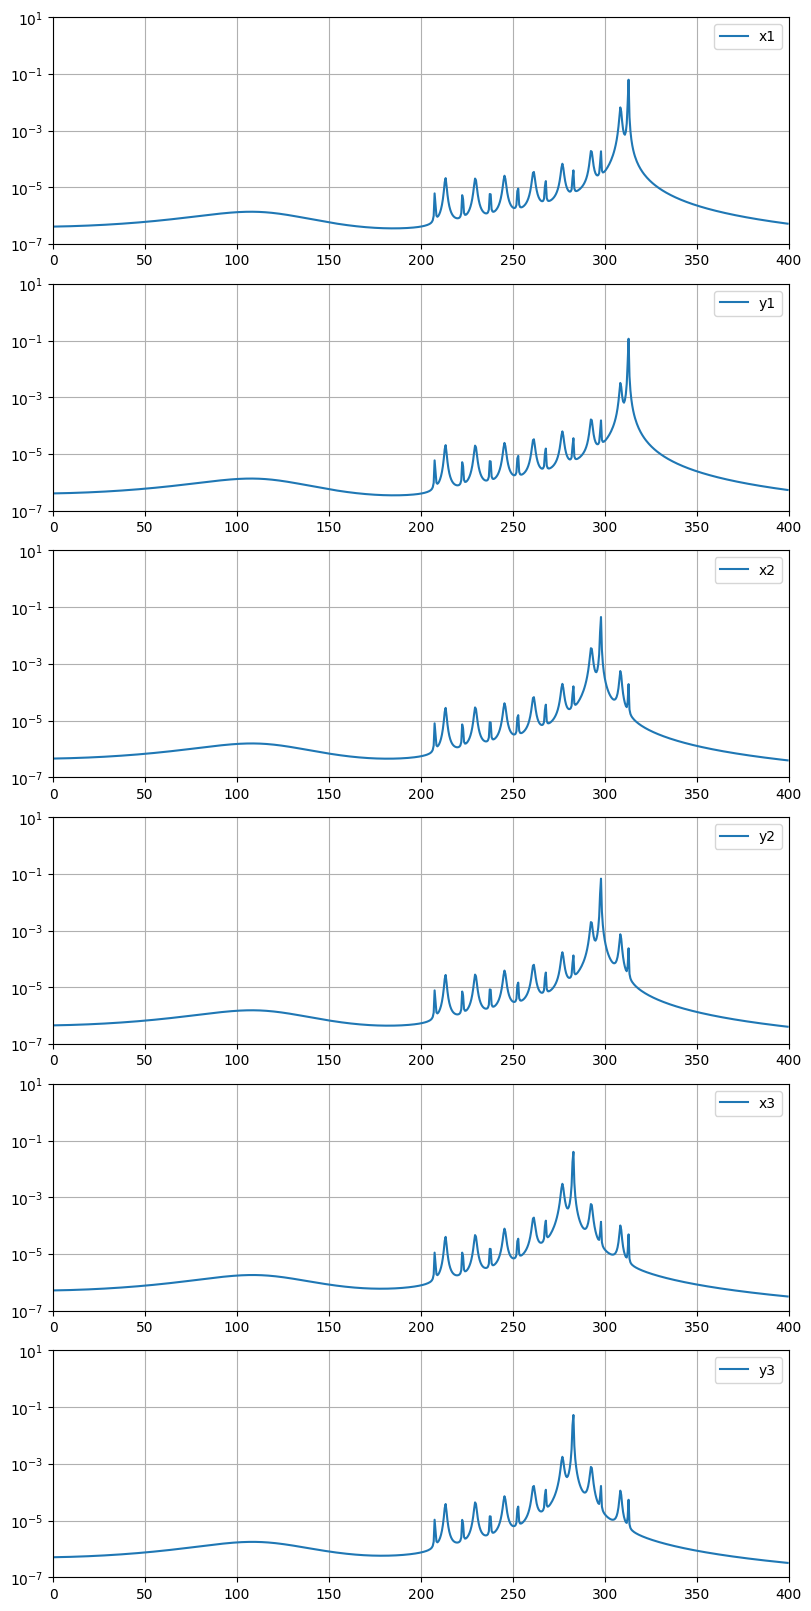

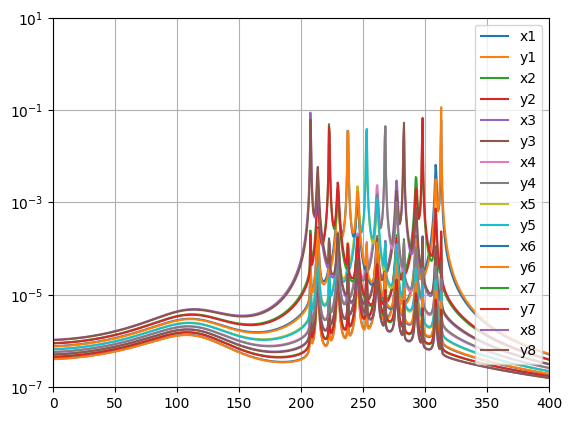

label='x1'
nx1 = 25.928828 phonons
Tx1 via phonons = 3.882489e-04 K
Tx1 via variance = 3.957357e-04 K
label='y1'
ny1 = 39.903918 phonons
Ty1 via phonons = 6.003795e-04 K
Ty1 via variance = 6.079023e-04 K
label='x2'
nx2 = 22.015988 phonons
Tx2 via phonons = 3.138104e-04 K
Tx2 via variance = 3.209373e-04 K
label='y2'
ny2 = 28.825885 phonons
Ty2 via phonons = 4.129521e-04 K
Ty2 via variance = 4.201150e-04 K
label='x3'
nx3 = 21.642498 phonons
Tx3 via phonons = 2.929067e-04 K
Tx3 via variance = 2.996736e-04 K
label='y3'
ny3 = 26.050335 phonons
Ty3 via phonons = 3.544371e-04 K
Ty3 via variance = 3.612400e-04 K
label='x4'
nx4 = 22.279516 phonons
Tx4 via phonons = 2.854893e-04 K
Tx4 via variance = 2.918962e-04 K
label='y4'
ny4 = 25.108360 phonons
Ty4 via phonons = 3.235455e-04 K
Ty4 via variance = 3.299885e-04 K
label='x5'
nx5 = 23.591767 phonons
Tx5 via phonons = 2.853210e-04 K
Tx5 via variance = 2.913681e-04 K
label='y5'
ny5 = 24.999818 phonons
Ty5 via phonons = 3.041498e-04 K
Ty5 via varian

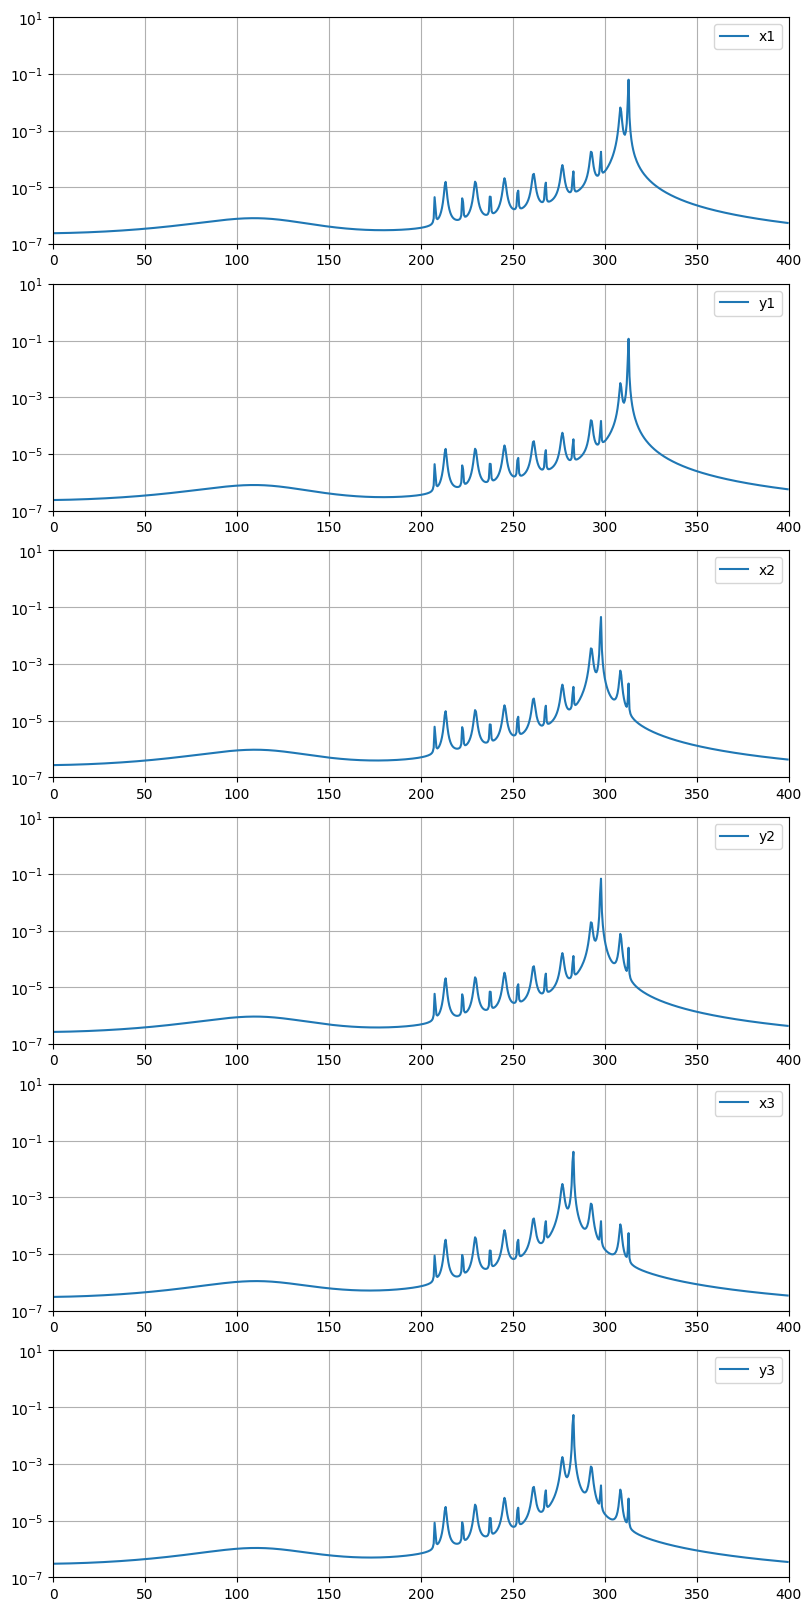

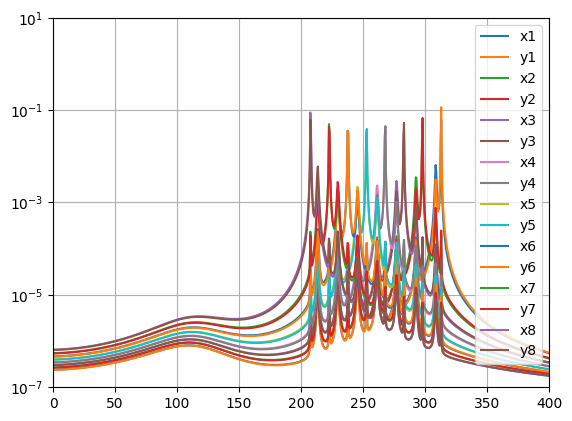

label='x1'
nx1 = 25.845181 phonons
Tx1 via phonons = 3.869964e-04 K
Tx1 via variance = 3.944832e-04 K
label='y1'
ny1 = 39.712261 phonons
Ty1 via phonons = 5.974959e-04 K
Ty1 via variance = 6.050187e-04 K
label='x2'
nx2 = 21.946799 phonons
Tx2 via phonons = 3.128242e-04 K
Tx2 via variance = 3.199511e-04 K
label='y2'
ny2 = 28.672393 phonons
Ty2 via phonons = 4.107533e-04 K
Ty2 via variance = 4.179161e-04 K
label='x3'
nx3 = 21.584724 phonons
Tx3 via phonons = 2.921247e-04 K
Tx3 via variance = 2.988917e-04 K
label='y3'
ny3 = 25.909361 phonons
Ty3 via phonons = 3.525190e-04 K
Ty3 via variance = 3.593219e-04 K
label='x4'
nx4 = 22.234776 phonons
Tx4 via phonons = 2.849160e-04 K
Tx4 via variance = 2.913229e-04 K
label='y4'
ny4 = 24.976157 phonons
Ty4 via phonons = 3.218419e-04 K
Ty4 via variance = 3.282849e-04 K
label='x5'
nx5 = 23.565520 phonons
Tx5 via phonons = 2.850036e-04 K
Tx5 via variance = 2.910506e-04 K
label='y5'
ny5 = 24.878433 phonons
Ty5 via phonons = 3.026730e-04 K
Ty5 via varian

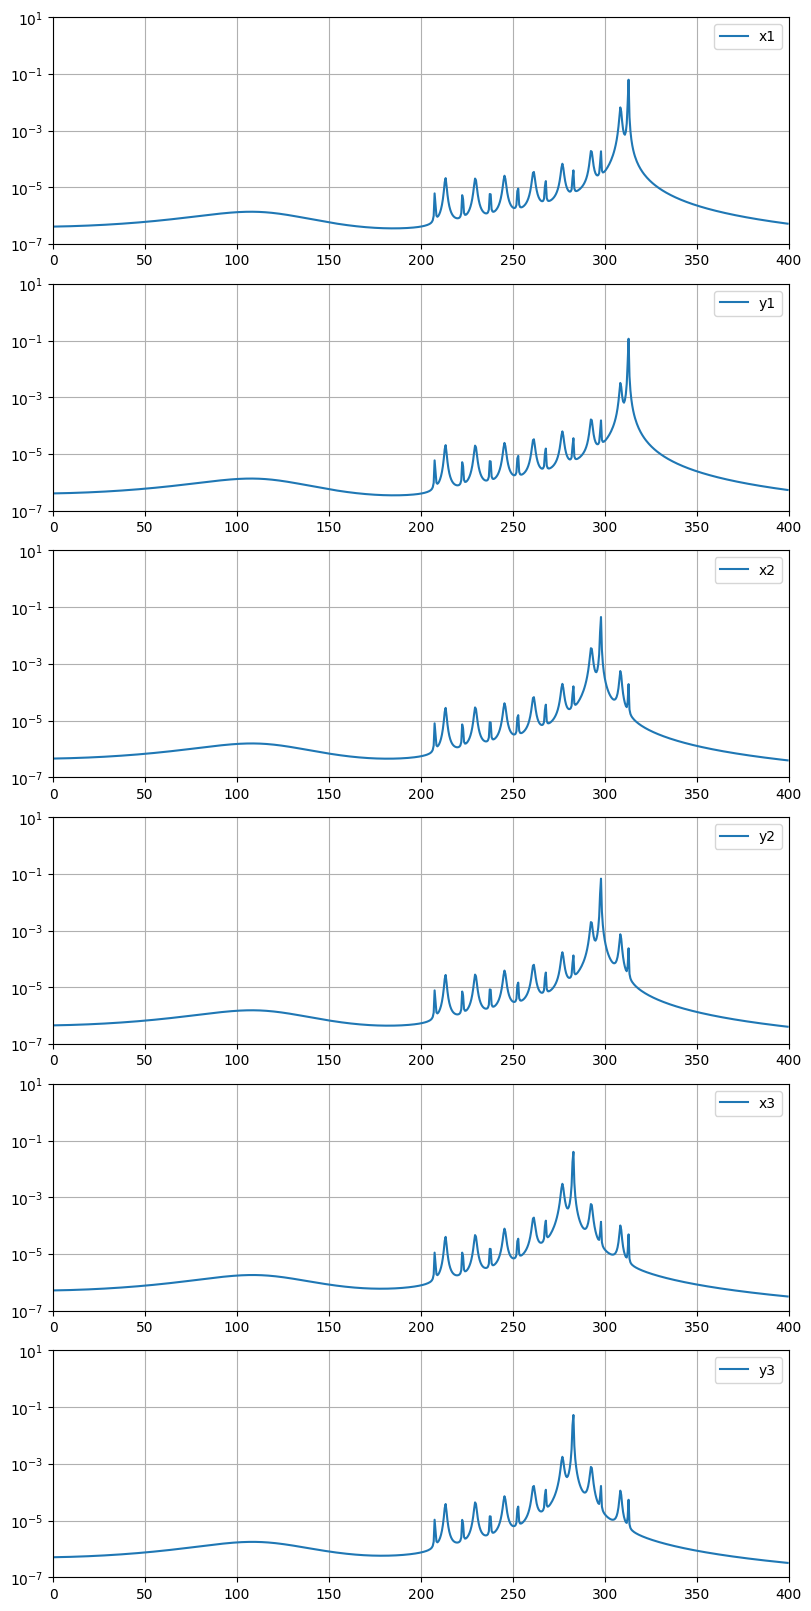

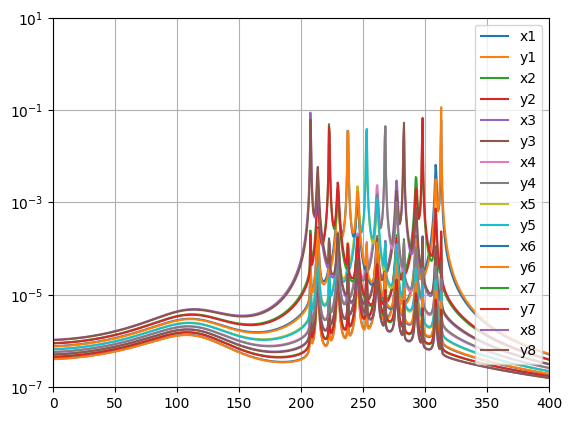

label='x1'
nx1 = 25.928828 phonons
Tx1 via phonons = 3.882489e-04 K
Tx1 via variance = 3.957357e-04 K
label='y1'
ny1 = 39.903918 phonons
Ty1 via phonons = 6.003795e-04 K
Ty1 via variance = 6.079023e-04 K
label='x2'
nx2 = 22.015988 phonons
Tx2 via phonons = 3.138104e-04 K
Tx2 via variance = 3.209373e-04 K
label='y2'
ny2 = 28.825885 phonons
Ty2 via phonons = 4.129521e-04 K
Ty2 via variance = 4.201150e-04 K
label='x3'
nx3 = 21.642498 phonons
Tx3 via phonons = 2.929067e-04 K
Tx3 via variance = 2.996736e-04 K
label='y3'
ny3 = 26.050335 phonons
Ty3 via phonons = 3.544371e-04 K
Ty3 via variance = 3.612400e-04 K
label='x4'
nx4 = 22.279516 phonons
Tx4 via phonons = 2.854893e-04 K
Tx4 via variance = 2.918962e-04 K
label='y4'
ny4 = 25.108360 phonons
Ty4 via phonons = 3.235455e-04 K
Ty4 via variance = 3.299885e-04 K
label='x5'
nx5 = 23.591767 phonons
Tx5 via phonons = 2.853210e-04 K
Tx5 via variance = 2.913681e-04 K
label='y5'
ny5 = 24.999818 phonons
Ty5 via phonons = 3.041498e-04 K
Ty5 via varian

AssertionError: 🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️ Failure present! 🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️
results_dict={'PSDs': {(LAM, TNT LAM): False, (TNT LAM, Numerical H): False, (LAM, Numerical H): True}}

In [2]:
# NOTE: these toy_params and kwargs are the only things needed to match the Fortran
toy_params = {
    'model': 'pairs',
    'first_Ωx': 312*kHz,
    'Ω_gap': 15*kHz,
    'Ωz_to_Ωx_multiplier': 10,

    'toy_gx': -40*kHz,
    'toy_gy': -40*kHz,

    'use_Γ_formula': True,
}
cavity_kwargs = {
    'Δ': -450*kHz,
    'L': 0.96*cm,
    'Finesse': 40_000,
    'θhom': π/4,
}
gas_kwargs = {
    'P': 1e-6*mbar,
    'T': 300*K,
}
N, ax = 8, 2
ω_low, ω_high, ω_step = 0, 400, 0.5
mph = MultiPhysics(
    num_traps=N,
    Cartesian_axes_per_trap=ax,
    ω_range=np.arange(ω_low, ω_high, ω_step) * kHz,

    cavity_kwargs=cavity_kwargs,
    gas_kwargs=gas_kwargs,
    toy_params=toy_params,
)

mph.info
mph.cavity.info
mph.gas.info
mph.info_per_dimension

methods = [
    QLTM.LINEAR_AMPLIFIER_MODEL,
    QLTM.TNT_LINEAR_AMPLIFIER_MODEL,
    QLTM.NUMERICAL_HYBRIDISATION,
]
spectra_to_compare = ['PSDs']
compare_methods(mph, methods, spectra_to_compare)


# $1 \times 2$ Antonio's paper parameters
From
`2024-09-07 -- Deplano, Pontin, Ranfagni, Marino, Marin -- High purity two-dimensional levitated mechanical oscillator -- arXiv.pdf`
(Need to define more properly the heterodyne spectrum...)

MultiPhysics(
    num_traps = 1
    Cartesian_axes_per_trap = 2
    ω_range = [-200.0, 199.8999999999772] kHz
    num_ω_points = 4000

    setup_hybridisation_power_series = True
    compare_Rjk_calculations = False

    id(gas) = 4385450000
    id(cavity) = 4385450448
)
toy_params = {
    type = custom
    Ωz_to_Ωx_multiplier = 10.0

    ρ = 2200.0 kg/m³
    r = 75.0 nm
    m = 3.88772e-18 kg

    P = 0.0 mbar
    T = 300.0 K
    〈v〉 = 500.0 m/s

    all Ωx = [120.] kHz
    all Ωy = [110.] kHz
    all Ωz = [12.] kHz

    Γ_formula = 2.94753e-05 Hz
    Γ_formula_from_Antonio_paper = (1 + π/8) m〈v〉P / (kBT) / (ρr) = 2.33519e-05 Hz
    Γ_formula_from_Tania_paper = 15Pr²/(m〈v〉) = 2.07248e-05 Hz
    Γ_formula_from_Tania_fortran = 16P/(πρr〈v〉) = 2.94753e-05 Hz

    gx = -15.00000 kHz
    gy = -10.00000 kHz
    gz = 0.00000 kHz

    gxy = 0.00000 kHz
    gxz = 0.00000 kHz
    gyz = 0.00000 kHz

}
Cavity(id=4385450448
    Length = 0.96000 cm
    waist = 61.00000 μm
    Finesse = 3.000e+05
   

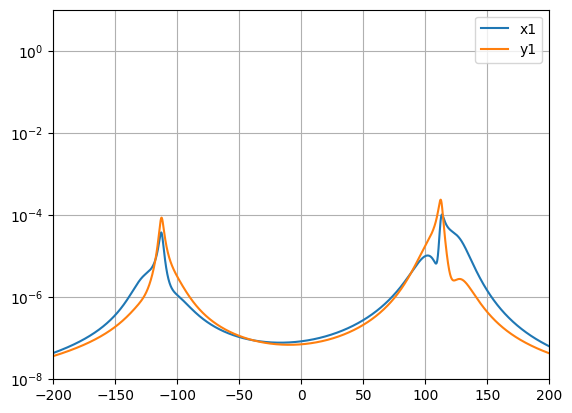

label='x1'
nx1 = 0.299104 phonons
Tx1 via phonons = 1.722566e-06 K
Tx1 via variance = 4.602112e-06 K
label='y1'
ny1 = 0.508803 phonons
Ty1 via phonons = 2.686055e-06 K
Ty1 via variance = 5.325639e-06 K
PSDs -- QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
Calculating all PSDs in frequency range [-200.0, 199.8999999999772]  kHz using QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
-200.0 kHz
-190.00000000000057 kHz
-180.00000000000114 kHz
-170.0000000000017 kHz
-160.00000000000227 kHz
-150.00000000000284 kHz
-140.0000000000034 kHz
-130.00000000000398 kHz
-120.00000000000455 kHz
-110.00000000000512 kHz
-100.00000000000568 kHz
-90.00000000000625 kHz
-80.00000000000682 kHz
-70.00000000000739 kHz
-60.00000000000795 kHz
-50.00000000000852 kHz
-40.000000000009095 kHz
-30.000000000009663 kHz
-20.000000000010232 kHz
-10.0000000000108 kHz
-1.1368683772161603e-11 kHz
9.999999999988063 kHz
19.999999999987494 kHz
29.999999999986926 kHz
39.99999999998636 kHz
49.99999999998579 kHz
59.9999

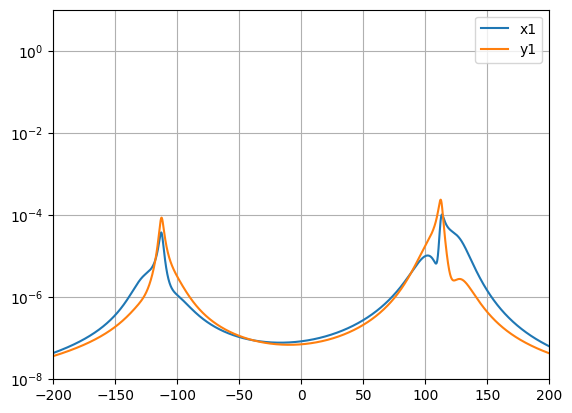

label='x1'
nx1 = 0.299104 phonons
Tx1 via phonons = 1.722566e-06 K
Tx1 via variance = 4.602112e-06 K
label='y1'
ny1 = 0.508803 phonons
Ty1 via phonons = 2.686055e-06 K
Ty1 via variance = 5.325639e-06 K
homodyne -- QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
Calculating homodyne spectrum in frequency range [-200.0, 199.8999999999772] kHz using QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
-200.0 kHz
-190.00000000000057 kHz
-180.00000000000114 kHz
-170.0000000000017 kHz
-160.00000000000227 kHz
-150.00000000000284 kHz
-140.0000000000034 kHz
-130.00000000000398 kHz
-120.00000000000455 kHz
-110.00000000000512 kHz
-100.00000000000568 kHz
-90.00000000000625 kHz
-80.00000000000682 kHz
-70.00000000000739 kHz
-60.00000000000795 kHz
-50.00000000000852 kHz
-40.000000000009095 kHz
-30.000000000009663 kHz
-20.000000000010232 kHz
-10.0000000000108 kHz
-1.1368683772161603e-11 kHz
9.999999999988063 kHz
19.999999999987494 kHz
29.999999999986926 kHz
39.99999999998636 kHz
49.99999999998579 kHz
59.

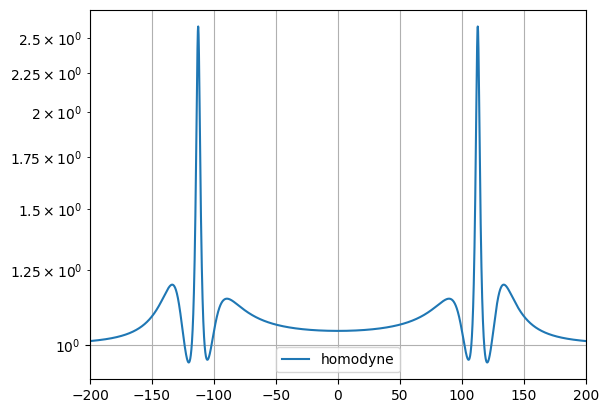

homodyne -- QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
Calculating homodyne spectrum in frequency range [-200.0, 199.8999999999772] kHz using QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
-200.0 kHz
-190.00000000000057 kHz
-180.00000000000114 kHz
-170.0000000000017 kHz
-160.00000000000227 kHz
-150.00000000000284 kHz
-140.0000000000034 kHz
-130.00000000000398 kHz
-120.00000000000455 kHz
-110.00000000000512 kHz
-100.00000000000568 kHz
-90.00000000000625 kHz
-80.00000000000682 kHz
-70.00000000000739 kHz
-60.00000000000795 kHz
-50.00000000000852 kHz
-40.000000000009095 kHz
-30.000000000009663 kHz
-20.000000000010232 kHz
-10.0000000000108 kHz
-1.1368683772161603e-11 kHz
9.999999999988063 kHz
19.999999999987494 kHz
29.999999999986926 kHz
39.99999999998636 kHz
49.99999999998579 kHz
59.99999999998522 kHz
69.99999999998465 kHz
79.99999999998408 kHz
89.99999999998352 kHz
99.99999999998295 kHz
109.99999999998238 kHz
119.99999999998181 kHz
129.99999999998124 kHz
139.99999999998067

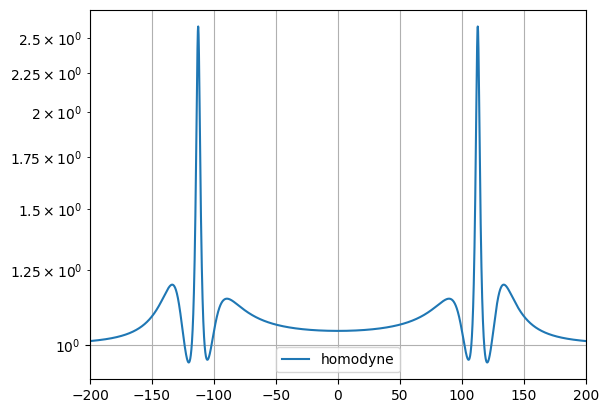

heterodyne -- QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
Calculating heterodyne spectrum in frequency range [-200.0, 199.8999999999772] kHz using QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
-200.0 kHz
-190.00000000000057 kHz
-180.00000000000114 kHz
-170.0000000000017 kHz
-160.00000000000227 kHz
-150.00000000000284 kHz
-140.0000000000034 kHz
-130.00000000000398 kHz
-120.00000000000455 kHz
-110.00000000000512 kHz
-100.00000000000568 kHz
-90.00000000000625 kHz
-80.00000000000682 kHz
-70.00000000000739 kHz
-60.00000000000795 kHz
-50.00000000000852 kHz
-40.000000000009095 kHz
-30.000000000009663 kHz
-20.000000000010232 kHz
-10.0000000000108 kHz
-1.1368683772161603e-11 kHz
9.999999999988063 kHz
19.999999999987494 kHz
29.999999999986926 kHz
39.99999999998636 kHz
49.99999999998579 kHz
59.99999999998522 kHz
69.99999999998465 kHz
79.99999999998408 kHz
89.99999999998352 kHz
99.99999999998295 kHz
109.99999999998238 kHz
119.99999999998181 kHz
129.99999999998124 kHz
139.99999999998067 kHz

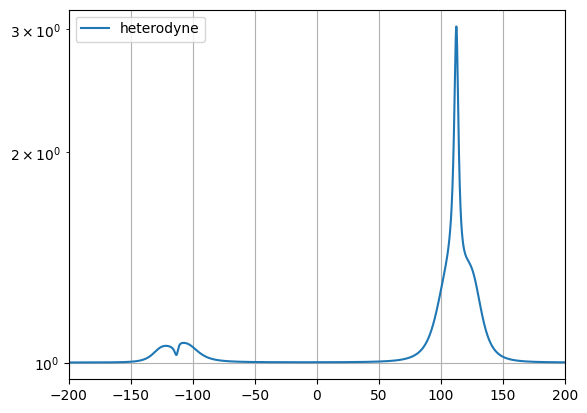

heterodyne -- QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
Calculating heterodyne spectrum in frequency range [-200.0, 199.8999999999772] kHz using QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
-200.0 kHz
-190.00000000000057 kHz
-180.00000000000114 kHz
-170.0000000000017 kHz
-160.00000000000227 kHz
-150.00000000000284 kHz
-140.0000000000034 kHz
-130.00000000000398 kHz
-120.00000000000455 kHz
-110.00000000000512 kHz
-100.00000000000568 kHz
-90.00000000000625 kHz
-80.00000000000682 kHz
-70.00000000000739 kHz
-60.00000000000795 kHz
-50.00000000000852 kHz
-40.000000000009095 kHz
-30.000000000009663 kHz
-20.000000000010232 kHz
-10.0000000000108 kHz
-1.1368683772161603e-11 kHz
9.999999999988063 kHz
19.999999999987494 kHz
29.999999999986926 kHz
39.99999999998636 kHz
49.99999999998579 kHz
59.99999999998522 kHz
69.99999999998465 kHz
79.99999999998408 kHz
89.99999999998352 kHz
99.99999999998295 kHz
109.99999999998238 kHz
119.99999999998181 kHz
129.99999999998124 kHz
139.9999999999

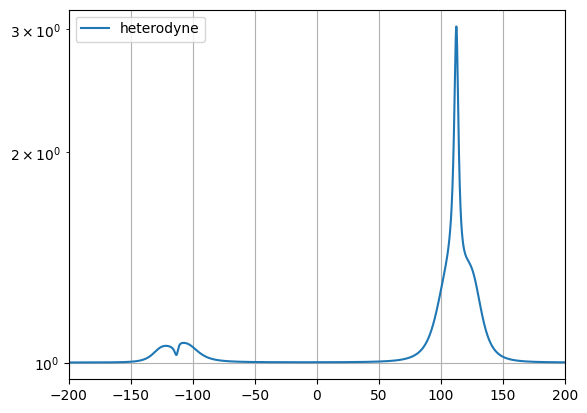

🎉🎉🎉🎉🎉 all spectral calculation methods agree :) 🎉🎉🎉🎉🎉
{'PSDs': {(LAM, Power Series H): True},
 'heterodyne': {(LAM, Power Series H): True},
 'homodyne': {(LAM, Power Series H): True}}


In [2]:
toy_params = {
    'model': 'custom',
    'Ωxs': [120*kHz],
    'Ωys': [110*kHz],

    'toy_gx': -15*kHz,
    'toy_gy': -10*kHz,

    'use_Γ_formula': True,
}
cavity_kwargs = {
    'Δ': -115*kHz,
    'L': 0.96*cm,
    'Finesse': 300_000,
    'θhom': π/4,
}
gas_kwargs = {
    'P': 3e-8*mbar,
    'T': 300*K,
    'vth': 500,  # m/s
}
N, ax = 1, 2
ω_low, ω_high, ω_step = -200, 200, 0.1
mph = MultiPhysics(
    num_traps=N,
    Cartesian_axes_per_trap=ax,
    ω_range=np.arange(ω_low, ω_high, ω_step) * kHz,

    cavity_kwargs=cavity_kwargs,
    gas_kwargs=gas_kwargs,
    toy_params=toy_params,

    setup_hybridisation_power_series=True,
)

mph.info
mph.cavity.info
mph.gas.info
mph.info_per_dimension

methods = [
    QLTM.LINEAR_AMPLIFIER_MODEL,
    QLTM.POWER_SERIES_HYBRIDISATION,
]
spectra_to_compare = [
    'PSDs',
    'homodyne',
    'heterodyne',
]
compare_methods(mph, methods, spectra_to_compare)


# $1 \times 3$: Compare LAM to Power Series Hybridisation
Apply mech-mech couplings but with no phase difference

MultiPhysics(
    num_traps = 1
    Cartesian_axes_per_trap = 3
    ω_range = [0.0, 399.5] kHz
    num_ω_points = 800

    setup_hybridisation_power_series = True
    compare_Rjk_calculations = False

    id(gas) = 6010683792
    id(cavity) = 6012172688
)
toy_params = {
    type = pairs
    first_Ωx = 312.0 kHz
    Ω_gap = 15.0 kHz
    Ωz_to_Ωx_multiplier = 10.0

    ρ = 2200.0 kg/m³
    r = 75.0 nm
    m = 3.88772e-18 kg

    P = 0.0 mbar
    T = 300.0 K
    〈v〉 = 500.0 m/s

    all Ωx = [312. 297.] kHz
    all Ωy = [313.5] kHz
    all Ωz = [31.2 29.7] kHz

    Γ_formula = 9.82508e-04 Hz
    Γ_formula_from_Antonio_paper = (1 + π/8) m〈v〉P / (kBT) / (ρr) = 7.78395e-04 Hz
    Γ_formula_from_Tania_paper = 15Pr²/(m〈v〉) = 6.90826e-04 Hz
    Γ_formula_from_Tania_fortran = 16P/(πρr〈v〉) = 9.82508e-04 Hz

    gx = -40.00000 kHz
    gy = -40.00000 kHz
    gz = 170.00000 kHz

    gxy = -2.00000 kHz
    gxz = -15.00000 kHz
    gyz = -15.00000 kHz

}
Cavity(id=6012172688
    Length = 0.96000 cm
   

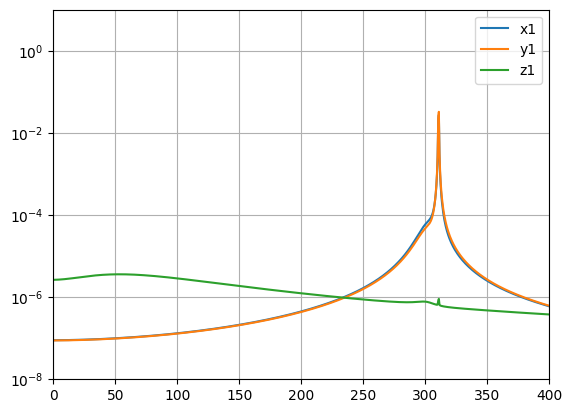

label='x1'
nx1 = 14.651090 phonons
Tx1 via phonons = 2.193801e-04 K
Tx1 via variance = 2.268669e-04 K
label='y1'
ny1 = 17.008348 phonons
Ty1 via phonons = 2.559013e-04 K
Ty1 via variance = 2.634241e-04 K
label='z1'
nz1 = -0.170992 phonons
Tz1 via phonons = -2.560366e-07 K
Tz1 via variance = 4.926453e-07 K
PSDs -- QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
Calculating all PSDs in frequency range [0.0, 399.5]  kHz using QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


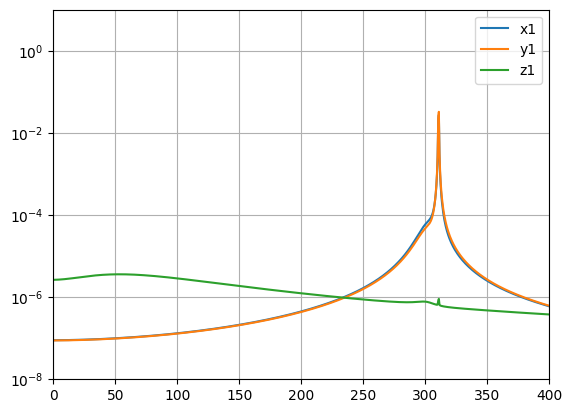

label='x1'
nx1 = 14.651090 phonons
Tx1 via phonons = 2.193801e-04 K
Tx1 via variance = 2.268669e-04 K
label='y1'
ny1 = 17.008348 phonons
Ty1 via phonons = 2.559013e-04 K
Ty1 via variance = 2.634241e-04 K
label='z1'
nz1 = -0.170992 phonons
Tz1 via phonons = -2.560366e-07 K
Tz1 via variance = 4.926453e-07 K
homodyne -- QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
Calculating homodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


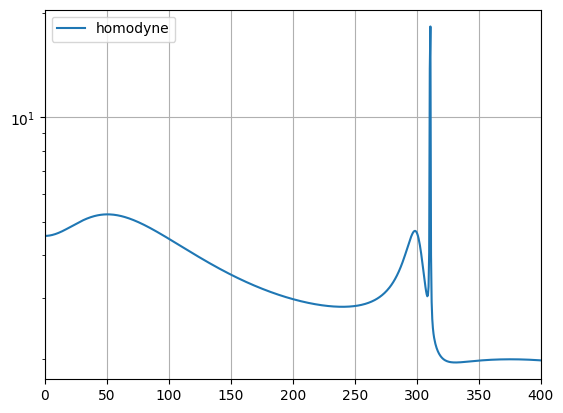

homodyne -- QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
Calculating homodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


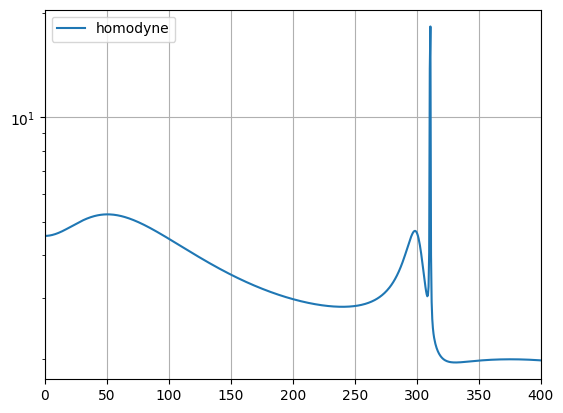

heterodyne -- QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
Calculating heterodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


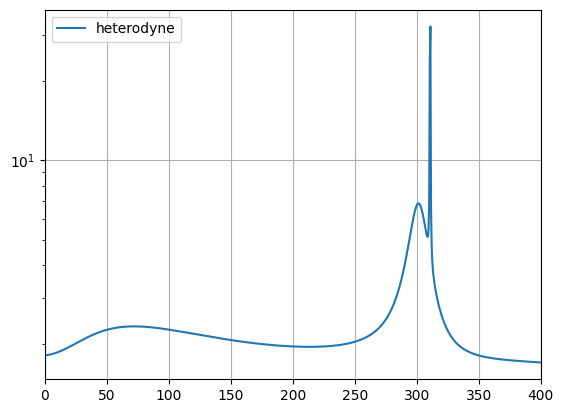

heterodyne -- QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
Calculating heterodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


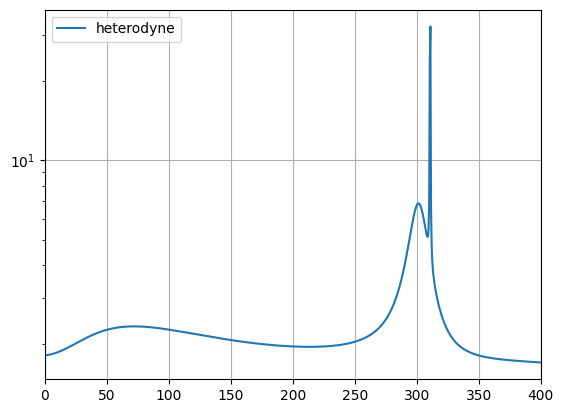

🎉🎉🎉🎉🎉 all spectral calculation methods agree :) 🎉🎉🎉🎉🎉
{'PSDs': {(LAM, Power Series H): True},
 'heterodyne': {(LAM, Power Series H): True},
 'homodyne': {(LAM, Power Series H): True}}


In [3]:
toy_params = {
    'model': 'pairs',
    'first_Ωx': 312*kHz,
    'Ω_gap': 15*kHz,
    'Ωz_to_Ωx_multiplier': 10,

    'toy_gx': -40*kHz,
    'toy_gy': -40*kHz,
    'toy_gz': +170*kHz,
    'gxy': -2*kHz,
    'gxz': -15*kHz,
    'gyz': -15*kHz,

    'use_Γ_formula': True,
}
cavity_kwargs = {
    'Δ': -450*kHz,
    'L': 0.96*cm,
    'Finesse': 40_000,
    'θhom': π/4,
}
gas_kwargs = {
    'P': 1e-6*mbar,
    'T': 300*K,
    'vth': 500,  # m/s
}
N, ax = 1, 3
ω_low, ω_high, ω_step = 0, 400, 0.5
mph = MultiPhysics(
    num_traps=N,
    Cartesian_axes_per_trap=ax,
    ω_range=np.arange(ω_low, ω_high, ω_step) * kHz,

    cavity_kwargs=cavity_kwargs,
    gas_kwargs=gas_kwargs,
    toy_params=toy_params,

    setup_hybridisation_power_series=True,
)

mph.info
mph.cavity.info
mph.gas.info
mph.info_per_dimension

methods = [
    QLTM.LINEAR_AMPLIFIER_MODEL,
    QLTM.POWER_SERIES_HYBRIDISATION,
]
spectra_to_compare = [
    'PSDs',
    'homodyne',
    'heterodyne',
]
compare_methods(mph, methods, spectra_to_compare)


# $2 \times 3$: Compare LAM to Power Series Hybridisation
Apply mech-mech couplings and a phase difference

MultiPhysics(
    num_traps = 2
    Cartesian_axes_per_trap = 3
    ω_range = [0.0, 398.0] kHz
    num_ω_points = 200

    setup_hybridisation_power_series = True
    compare_Rjk_calculations = False

    id(gas) = 5991658896
    id(cavity) = 6007490640
)
toy_params = {
    type = pairs
    first_Ωx = 312.0 kHz
    Ω_gap = 15.0 kHz
    Ωz_to_Ωx_multiplier = 10.0

    ρ = 2200.0 kg/m³
    r = 75.0 nm
    m = 3.88772e-18 kg

    P = 0.0 mbar
    T = 300.0 K
    〈v〉 = 500.0 m/s

    all Ωx = [312. 297. 282.] kHz
    all Ωy = [313.5 298.5] kHz
    all Ωz = [31.2 29.7 28.2] kHz

    Γ_formula = 9.82508e-04 Hz
    Γ_formula_from_Antonio_paper = (1 + π/8) m〈v〉P / (kBT) / (ρr) = 7.78395e-04 Hz
    Γ_formula_from_Tania_paper = 15Pr²/(m〈v〉) = 6.90826e-04 Hz
    Γ_formula_from_Tania_fortran = 16P/(πρr〈v〉) = 9.82508e-04 Hz

    gx = -40.00000 kHz
    gy = -40.00000 kHz
    gz = 170.00000 kHz

    gxy = -2.00000 kHz
    gxz = -15.00000 kHz
    gyz = -15.00000 kHz

}
Cavity(id=6007490640
    Length 

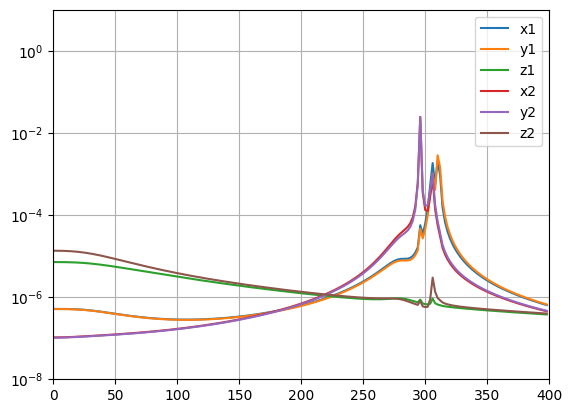

label='x1'
nx1 = 6.349915 phonons
Tx1 via phonons = 9.508133e-05 K
Tx1 via variance = 1.025681e-04 K
label='y1'
ny1 = 6.524540 phonons
Ty1 via phonons = 9.816579e-05 K
Ty1 via variance = 1.056886e-04 K
label='z1'
nz1 = -0.056128 phonons
Tz1 via phonons = -8.404360e-08 K
Tz1 via variance = 6.646383e-07 K
label='x2'
nx2 = 27.198442 phonons
Tx2 via phonons = 3.876799e-04 K
Tx2 via variance = 3.948067e-04 K
label='y2'
ny2 = 27.645704 phonons
Ty2 via phonons = 3.960452e-04 K
Ty2 via variance = 4.032081e-04 K
label='z2'
nz2 = 0.131404 phonons
Tz2 via phonons = 1.873000e-07 K
Tz2 via variance = 8.999876e-07 K
PSDs -- QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
Calculating all PSDs in frequency range [0.0, 398.0]  kHz using QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
0.0 kHz
200.0 kHz


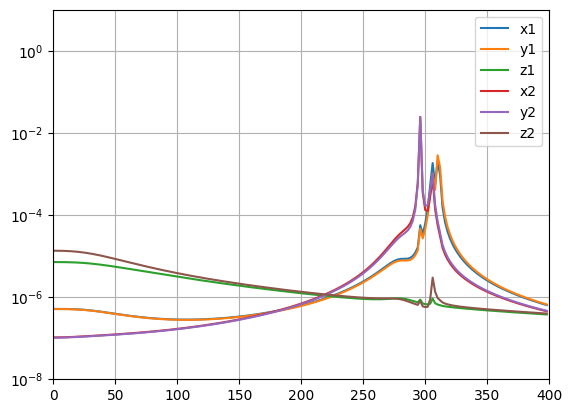

label='x1'
nx1 = 6.349915 phonons
Tx1 via phonons = 9.508133e-05 K
Tx1 via variance = 1.025681e-04 K
label='y1'
ny1 = 6.524540 phonons
Ty1 via phonons = 9.816579e-05 K
Ty1 via variance = 1.056886e-04 K
label='z1'
nz1 = -0.056128 phonons
Tz1 via phonons = -8.404360e-08 K
Tz1 via variance = 6.646383e-07 K
label='x2'
nx2 = 27.198442 phonons
Tx2 via phonons = 3.876799e-04 K
Tx2 via variance = 3.948067e-04 K
label='y2'
ny2 = 27.645704 phonons
Ty2 via phonons = 3.960452e-04 K
Ty2 via variance = 4.032081e-04 K
label='z2'
nz2 = 0.131404 phonons
Tz2 via phonons = 1.873000e-07 K
Tz2 via variance = 8.999876e-07 K
homodyne -- QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
Calculating homodyne spectrum in frequency range [0.0, 398.0] kHz using QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
0.0 kHz
200.0 kHz


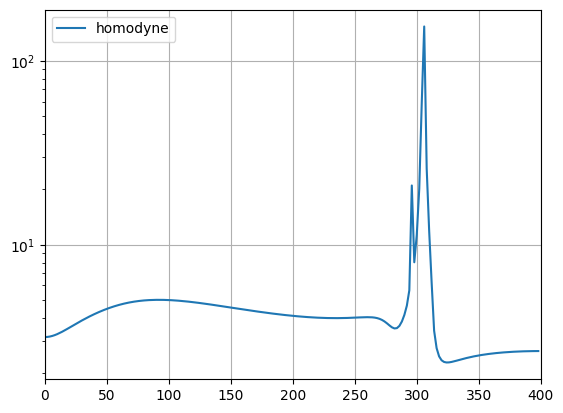

homodyne -- QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
Calculating homodyne spectrum in frequency range [0.0, 398.0] kHz using QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
0.0 kHz
200.0 kHz


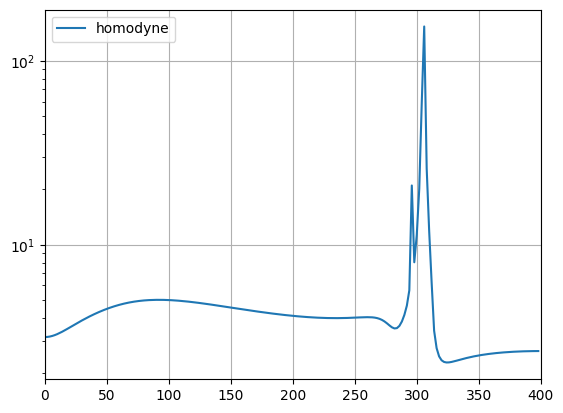

heterodyne -- QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
Calculating heterodyne spectrum in frequency range [0.0, 398.0] kHz using QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
0.0 kHz
200.0 kHz


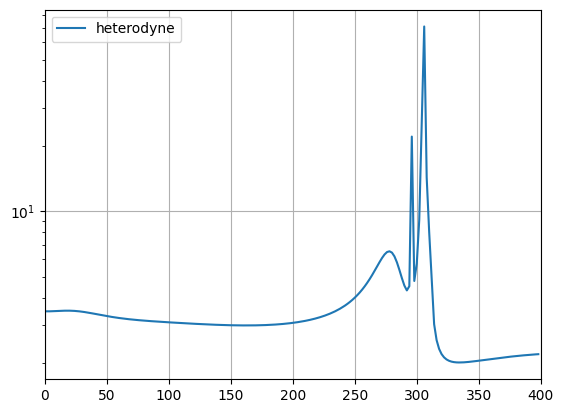

heterodyne -- QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
Calculating heterodyne spectrum in frequency range [0.0, 398.0] kHz using QuantumLinearTheoryMethod.POWER_SERIES_HYBRIDISATION
0.0 kHz
200.0 kHz


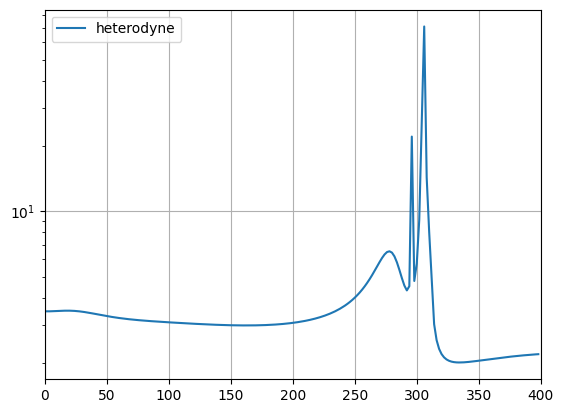

🎉🎉🎉🎉🎉 all spectral calculation methods agree :) 🎉🎉🎉🎉🎉
{'PSDs': {(LAM, Power Series H): True},
 'heterodyne': {(LAM, Power Series H): True},
 'homodyne': {(LAM, Power Series H): True}}


In [5]:
toy_params = {
    'model': 'pairs',
    'first_Ωx': 312*kHz,
    'Ω_gap': 15*kHz,
    'Ωz_to_Ωx_multiplier': 10,

    'toy_gx': -40*kHz,
    'toy_gy': -40*kHz,
    'toy_gz': +170*kHz,
    'gxy': -2*kHz,
    'gxz': -15*kHz,
    'gyz': -15*kHz,

    'use_Γ_formula': True,

    'φ1': 0*degrees,
    'φ2': 45*degrees,
}
cavity_kwargs = {
    'Δ': -450*kHz,
    'L': 0.96*cm,
    'Finesse': 40_000,
    'θhom': π/4,
}
gas_kwargs = {
    'P': 1e-6*mbar,
    'T': 300*K,
    'vth': 500,  # m/s
}
N, ax = 2, 3
# doing 2kHz step here speeds this up somewhat...
ω_low, ω_high, ω_step = 0, 400, 2
mph = MultiPhysics(
    num_traps=N,
    Cartesian_axes_per_trap=ax,
    ω_range=np.arange(ω_low, ω_high, ω_step) * kHz,

    cavity_kwargs=cavity_kwargs,
    gas_kwargs=gas_kwargs,
    toy_params=toy_params,

    setup_hybridisation_power_series=True,
)

mph.info
mph.cavity.info
mph.gas.info
mph.info_per_dimension
φ12 = mph.dimensions['x1'].φ - mph.dimensions['x2'].φ / degrees
print(f'{φ12 / degrees} degrees')

methods = [
    QLTM.LINEAR_AMPLIFIER_MODEL,
    QLTM.POWER_SERIES_HYBRIDISATION,
]
spectra_to_compare = [
    'PSDs',
    'homodyne',
    'heterodyne',
]
compare_methods(mph, methods, spectra_to_compare)


# $1 \times 3$: Compare all other methods

MultiPhysics(
    num_traps = 1
    Cartesian_axes_per_trap = 3
    ω_range = [0.0, 399.5] kHz
    num_ω_points = 800

    setup_hybridisation_power_series = False
    compare_Rjk_calculations = False

    id(gas) = 6008372048
    id(cavity) = 4385436368
)
toy_params = {
    type = pairs
    first_Ωx = 312.0 kHz
    Ω_gap = 15.0 kHz
    Ωz_to_Ωx_multiplier = 10.0

    ρ = 2200.0 kg/m³
    r = 75.0 nm
    m = 3.88772e-18 kg

    P = 0.0 mbar
    T = 300.0 K
    〈v〉 = 468.8 m/s

    all Ωx = [312. 297.] kHz
    all Ωy = [313.5] kHz
    all Ωz = [31.2 29.7] kHz

    Γ_formula = 1.04798e-03 Hz
    Γ_formula_from_Antonio_paper = (1 + π/8) m〈v〉P / (kBT) / (ρr) = 7.29763e-04 Hz
    Γ_formula_from_Tania_paper = 15Pr²/(m〈v〉) = 7.36864e-04 Hz
    Γ_formula_from_Tania_fortran = 16P/(πρr〈v〉) = 1.04798e-03 Hz

    gx = -40.00000 kHz
    gy = -40.00000 kHz
    gz = 0.00000 kHz

    gxy = 0.00000 kHz
    gxz = 0.00000 kHz
    gyz = 0.00000 kHz

}
Cavity(id=4385436368
    Length = 0.96000 cm
    waist

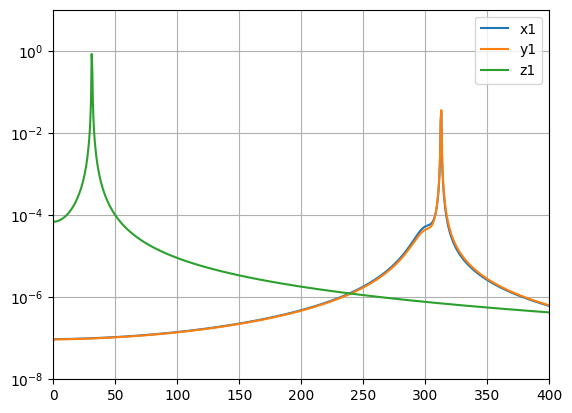

label='x1'
nx1 = 15.751074 phonons
Tx1 via phonons = 2.358509e-04 K
Tx1 via variance = 2.433377e-04 K
label='y1'
ny1 = 18.151639 phonons
Ty1 via phonons = 2.731028e-04 K
Ty1 via variance = 2.806256e-04 K
label='z1'
nz1 = 364.048641 phonons
Tz1 via phonons = 5.451133e-04 K
Tz1 via variance = 5.458620e-04 K
PSDs -- QuantumLinearTheoryMethod.HYBRID_LINEAR_AMPLIFIER_MODEL
Calculating all PSDs in frequency range [0.0, 399.5]  kHz using QuantumLinearTheoryMethod.HYBRID_LINEAR_AMPLIFIER_MODEL
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


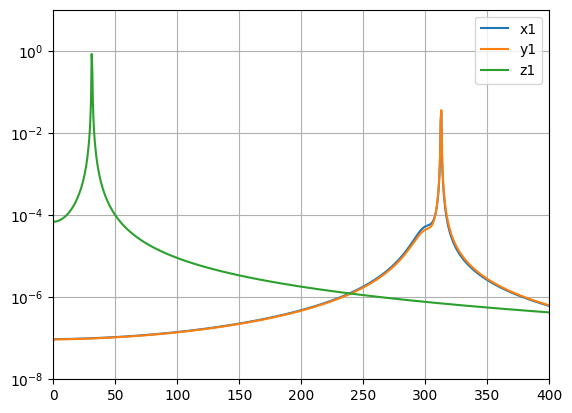

label='x1'
nx1 = 15.751074 phonons
Tx1 via phonons = 2.358509e-04 K
Tx1 via variance = 2.433377e-04 K
label='y1'
ny1 = 18.151639 phonons
Ty1 via phonons = 2.731028e-04 K
Ty1 via variance = 2.806256e-04 K
label='z1'
nz1 = 364.048641 phonons
Tz1 via phonons = 5.451133e-04 K
Tz1 via variance = 5.458620e-04 K
PSDs -- QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION
Calculating all PSDs in frequency range [0.0, 399.5]  kHz using QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


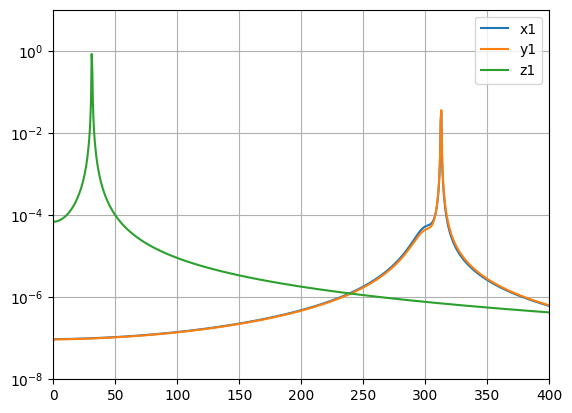

label='x1'
nx1 = 15.751074 phonons
Tx1 via phonons = 2.358509e-04 K
Tx1 via variance = 2.433377e-04 K
label='y1'
ny1 = 18.151639 phonons
Ty1 via phonons = 2.731028e-04 K
Ty1 via variance = 2.806256e-04 K
label='z1'
nz1 = 364.048641 phonons
Tz1 via phonons = 5.451133e-04 K
Tz1 via variance = 5.458620e-04 K
homodyne -- QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
Calculating homodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


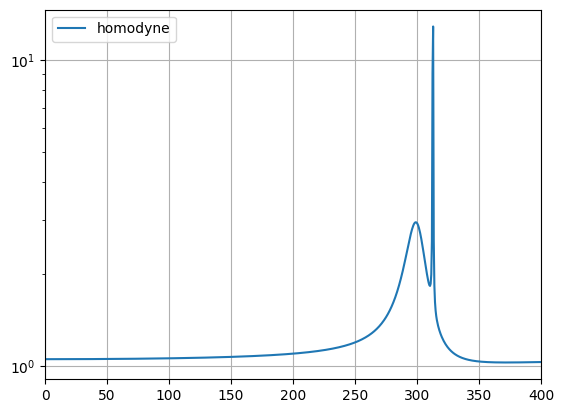

homodyne -- QuantumLinearTheoryMethod.HYBRID_LINEAR_AMPLIFIER_MODEL
Calculating homodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.HYBRID_LINEAR_AMPLIFIER_MODEL
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


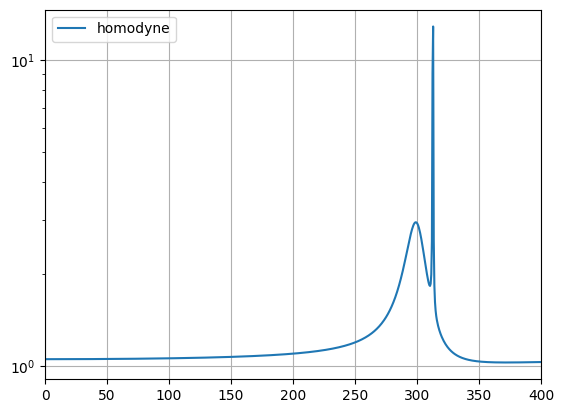

homodyne -- QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION
Calculating homodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


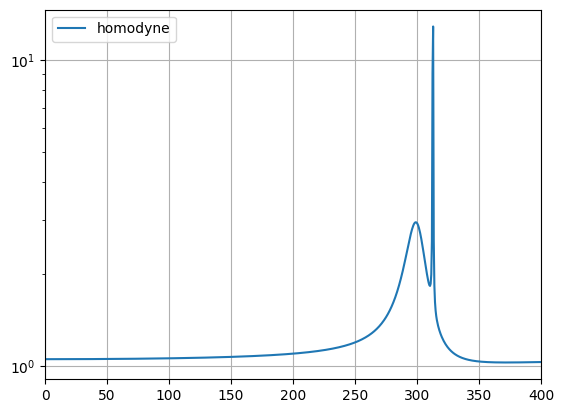

heterodyne -- QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
Calculating heterodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


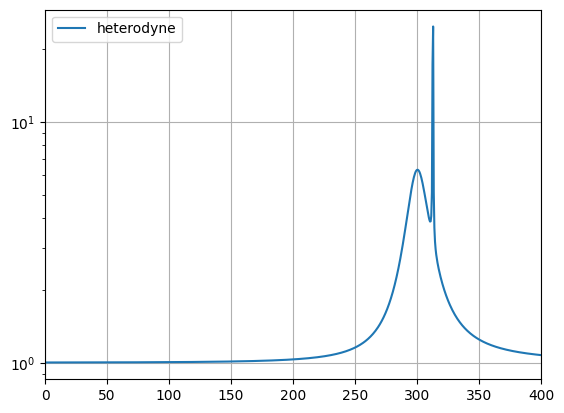

heterodyne -- QuantumLinearTheoryMethod.HYBRID_LINEAR_AMPLIFIER_MODEL
Calculating heterodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.HYBRID_LINEAR_AMPLIFIER_MODEL
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


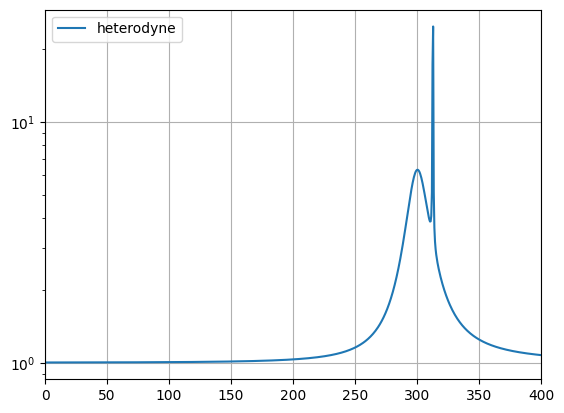

heterodyne -- QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION
Calculating heterodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


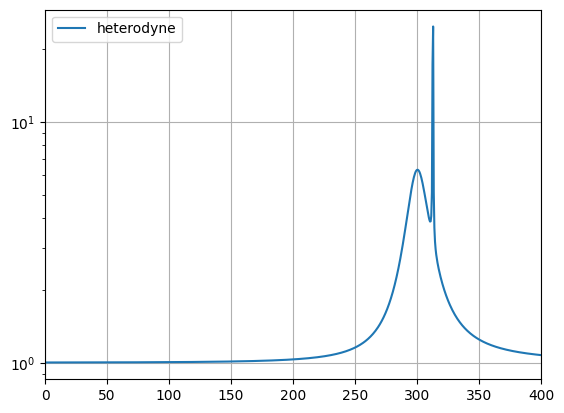

🎉🎉🎉🎉🎉 all spectral calculation methods agree :) 🎉🎉🎉🎉🎉
{'PSDs': {(LAM, Numerical H): True,
          (LAM, Hybrid LAM): True,
          (Hybrid LAM, Numerical H): True},
 'heterodyne': {(LAM, Numerical H): True,
                (LAM, Hybrid LAM): True,
                (Hybrid LAM, Numerical H): True},
 'homodyne': {(LAM, Numerical H): True,
              (LAM, Hybrid LAM): True,
              (Hybrid LAM, Numerical H): True}}


In [7]:
toy_params = {
    'model': 'pairs',
    'first_Ωx': 312*kHz,
    'Ω_gap': 15*kHz,
    'Ωz_to_Ωx_multiplier': 10,

    'toy_gx': -40*kHz,
    'toy_gy': -40*kHz,

    'use_Γ_formula': True,
}
cavity_kwargs = {
    'Δ': -450*kHz,
    'L': 0.96*cm,
    'Finesse': 40_000,
    'θhom': π/4,
}
gas_kwargs = {
    'P': 1e-6*mbar,
    'T': 300*K,
}
N, ax = 1, 3
ω_low, ω_high, ω_step = 0, 400, 0.5
mph = MultiPhysics(
    num_traps=N,
    Cartesian_axes_per_trap=ax,
    ω_range=np.arange(ω_low, ω_high, ω_step) * kHz,

    cavity_kwargs=cavity_kwargs,
    gas_kwargs=gas_kwargs,
    toy_params=toy_params,

    setup_hybridisation_power_series=False,
    compare_Rjk_calculations=False,
)

mph.info
mph.cavity.info
mph.gas.info
mph.info_per_dimension

methods = [
    QLTM.LINEAR_AMPLIFIER_MODEL,
    QLTM.HYBRID_LINEAR_AMPLIFIER_MODEL,
    QLTM.NUMERICAL_HYBRIDISATION,
]
spectra_to_compare = [
    'PSDs',
    'homodyne',
    'heterodyne',
]
compare_methods(mph, methods, spectra_to_compare)


# $2 \times 3$: Compare all other methods

MultiPhysics(
    num_traps = 2
    Cartesian_axes_per_trap = 3
    ω_range = [0.0, 399.5] kHz
    num_ω_points = 800

    setup_hybridisation_power_series = False
    compare_Rjk_calculations = False

    id(gas) = 6010960656
    id(cavity) = 6010953744
)
toy_params = {
    type = pairs
    first_Ωx = 312.0 kHz
    Ω_gap = 15.0 kHz
    Ωz_to_Ωx_multiplier = 10.0

    ρ = 2200.0 kg/m³
    r = 75.0 nm
    m = 3.88772e-18 kg

    P = 0.0 mbar
    T = 300.0 K
    〈v〉 = 500.0 m/s

    all Ωx = [312. 297. 282.] kHz
    all Ωy = [313.5 298.5] kHz
    all Ωz = [31.2 29.7 28.2] kHz

    Γ_formula = 9.82508e-04 Hz
    Γ_formula_from_Antonio_paper = (1 + π/8) m〈v〉P / (kBT) / (ρr) = 7.78395e-04 Hz
    Γ_formula_from_Tania_paper = 15Pr²/(m〈v〉) = 6.90826e-04 Hz
    Γ_formula_from_Tania_fortran = 16P/(πρr〈v〉) = 9.82508e-04 Hz

    gx = -40.00000 kHz
    gy = -40.00000 kHz
    gz = 170.00000 kHz

    gxy = -2.00000 kHz
    gxz = -15.00000 kHz
    gyz = -15.00000 kHz

}
Cavity(id=6010953744
    Length

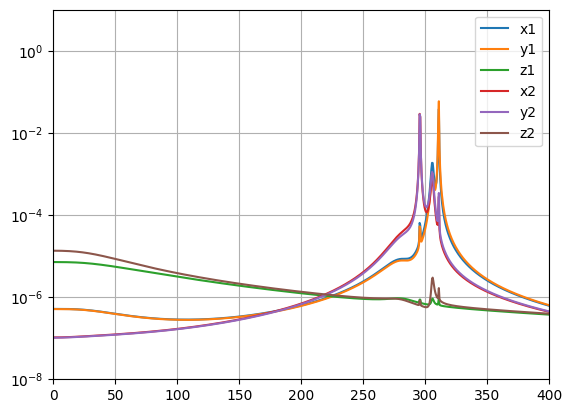

label='x1'
nx1 = 17.773521 phonons
Tx1 via phonons = 2.661343e-04 K
Tx1 via variance = 2.736211e-04 K
label='y1'
ny1 = 24.245172 phonons
Ty1 via phonons = 3.647838e-04 K
Ty1 via variance = 3.723066e-04 K
label='z1'
nz1 = -0.055843 phonons
Tz1 via phonons = -8.361659e-08 K
Tz1 via variance = 6.650653e-07 K
label='x2'
nx2 = 17.924655 phonons
Tx2 via phonons = 2.554936e-04 K
Tx2 via variance = 2.626205e-04 K
label='y2'
ny2 = 18.156615 phonons
Ty2 via phonons = 2.601070e-04 K
Ty2 via variance = 2.672698e-04 K
label='z2'
nz2 = 0.131612 phonons
Tz2 via phonons = 1.875969e-07 K
Tz2 via variance = 9.002845e-07 K
PSDs -- QuantumLinearTheoryMethod.HYBRID_LINEAR_AMPLIFIER_MODEL
Calculating all PSDs in frequency range [0.0, 399.5]  kHz using QuantumLinearTheoryMethod.HYBRID_LINEAR_AMPLIFIER_MODEL
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


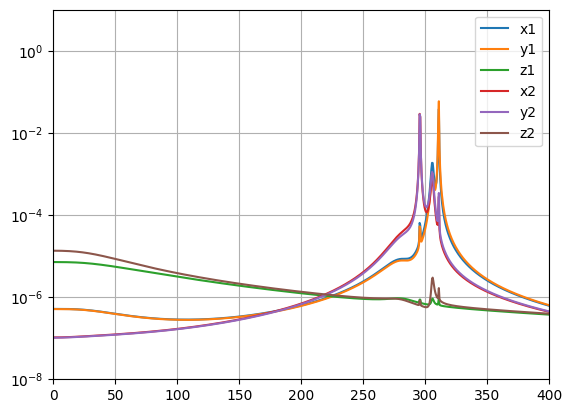

label='x1'
nx1 = 17.773521 phonons
Tx1 via phonons = 2.661343e-04 K
Tx1 via variance = 2.736211e-04 K
label='y1'
ny1 = 24.245172 phonons
Ty1 via phonons = 3.647838e-04 K
Ty1 via variance = 3.723066e-04 K
label='z1'
nz1 = -0.055843 phonons
Tz1 via phonons = -8.361659e-08 K
Tz1 via variance = 6.650653e-07 K
label='x2'
nx2 = 17.924655 phonons
Tx2 via phonons = 2.554936e-04 K
Tx2 via variance = 2.626205e-04 K
label='y2'
ny2 = 18.156615 phonons
Ty2 via phonons = 2.601070e-04 K
Ty2 via variance = 2.672698e-04 K
label='z2'
nz2 = 0.131612 phonons
Tz2 via phonons = 1.875969e-07 K
Tz2 via variance = 9.002845e-07 K
PSDs -- QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION
Calculating all PSDs in frequency range [0.0, 399.5]  kHz using QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


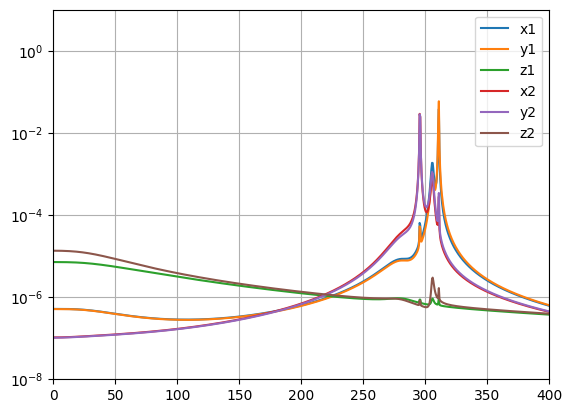

label='x1'
nx1 = 17.773521 phonons
Tx1 via phonons = 2.661343e-04 K
Tx1 via variance = 2.736211e-04 K
label='y1'
ny1 = 24.245172 phonons
Ty1 via phonons = 3.647838e-04 K
Ty1 via variance = 3.723066e-04 K
label='z1'
nz1 = -0.055843 phonons
Tz1 via phonons = -8.361659e-08 K
Tz1 via variance = 6.650653e-07 K
label='x2'
nx2 = 17.924655 phonons
Tx2 via phonons = 2.554936e-04 K
Tx2 via variance = 2.626205e-04 K
label='y2'
ny2 = 18.156615 phonons
Ty2 via phonons = 2.601070e-04 K
Ty2 via variance = 2.672698e-04 K
label='z2'
nz2 = 0.131612 phonons
Tz2 via phonons = 1.875969e-07 K
Tz2 via variance = 9.002845e-07 K
homodyne -- QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
Calculating homodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


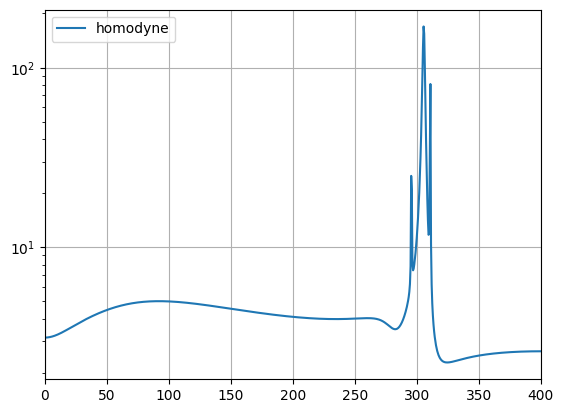

homodyne -- QuantumLinearTheoryMethod.HYBRID_LINEAR_AMPLIFIER_MODEL
Calculating homodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.HYBRID_LINEAR_AMPLIFIER_MODEL
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


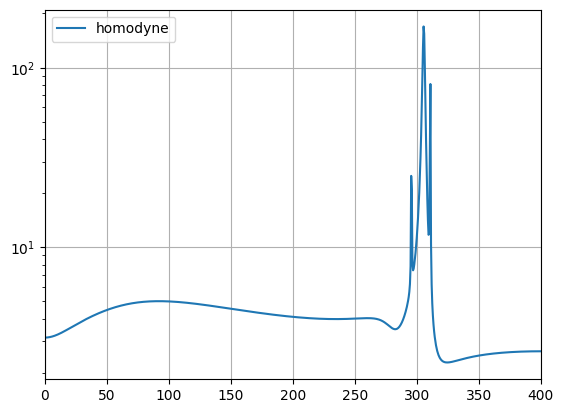

homodyne -- QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION
Calculating homodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


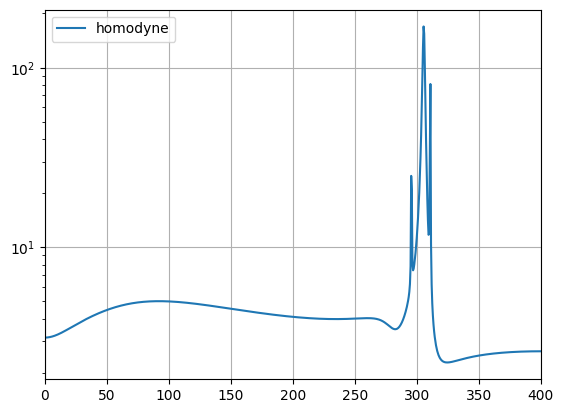

heterodyne -- QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
Calculating heterodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


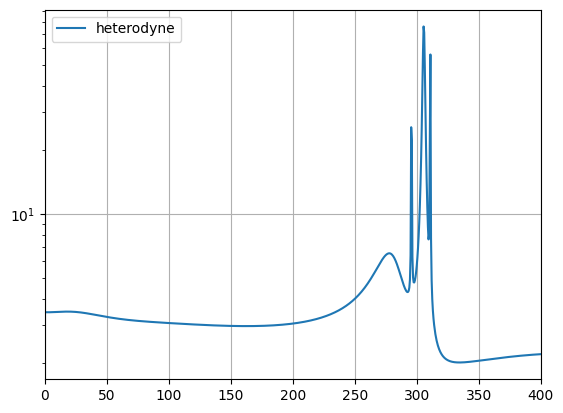

heterodyne -- QuantumLinearTheoryMethod.HYBRID_LINEAR_AMPLIFIER_MODEL
Calculating heterodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.HYBRID_LINEAR_AMPLIFIER_MODEL
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


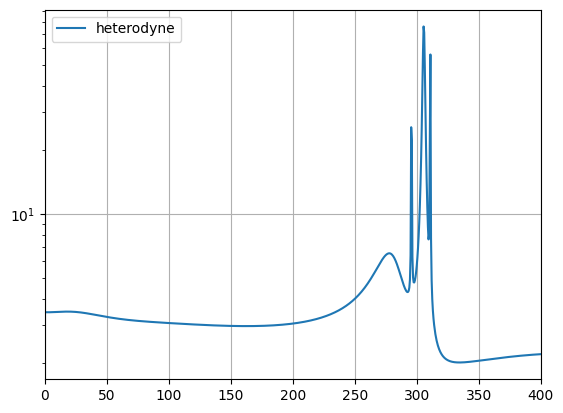

heterodyne -- QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION
Calculating heterodyne spectrum in frequency range [0.0, 399.5] kHz using QuantumLinearTheoryMethod.NUMERICAL_HYBRIDISATION
0.0 kHz
50.0 kHz
100.0 kHz
150.0 kHz
200.0 kHz
250.0 kHz
300.0 kHz
350.0 kHz


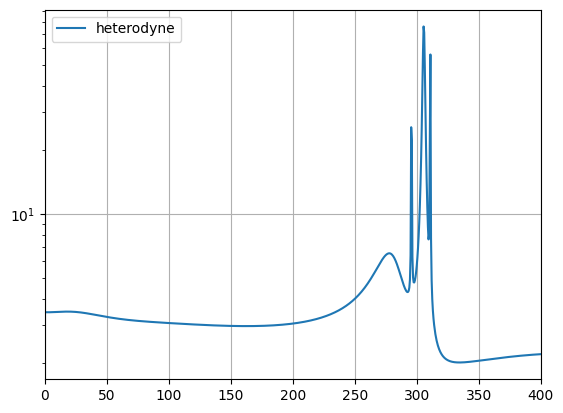

🎉🎉🎉🎉🎉 all spectral calculation methods agree :) 🎉🎉🎉🎉🎉
{'PSDs': {(LAM, Hybrid LAM): True,
          (Hybrid LAM, Numerical H): True,
          (LAM, Numerical H): True},
 'heterodyne': {(LAM, Hybrid LAM): True,
                (Hybrid LAM, Numerical H): True,
                (LAM, Numerical H): True},
 'homodyne': {(LAM, Hybrid LAM): True,
              (Hybrid LAM, Numerical H): True,
              (LAM, Numerical H): True}}


In [9]:
toy_params = {
    'model': 'pairs',
    'first_Ωx': 312*kHz,
    'Ω_gap': 15*kHz,
    'Ωz_to_Ωx_multiplier': 10,

    'toy_gx': -40*kHz,
    'toy_gy': -40*kHz,
    'toy_gz': +170*kHz,
    'gxy': -2*kHz,
    'gxz': -15*kHz,
    'gyz': -15*kHz,

    'use_Γ_formula': True,

    'φ1': 0*degrees,
    'φ2': 45*degrees,
}
cavity_kwargs = {
    'Δ': -450*kHz,
    'L': 0.96*cm,
    'Finesse': 40_000,
    'θhom': π/4,
}
gas_kwargs = {
    'P': 1e-6*mbar,
    'T': 300*K,
    'vth': 500,  # m/s
}
N, ax = 2, 3
ω_low, ω_high, ω_step = 0, 400, 0.5
mph = MultiPhysics(
    num_traps=N,
    Cartesian_axes_per_trap=ax,
    ω_range=np.arange(ω_low, ω_high, ω_step) * kHz,

    cavity_kwargs=cavity_kwargs,
    gas_kwargs=gas_kwargs,
    toy_params=toy_params,
)

mph.info
mph.cavity.info
mph.gas.info
mph.info_per_dimension
φ12 = mph.dimensions['x1'].φ - mph.dimensions['x2'].φ / degrees
print(f'{φ12 / degrees} degrees')

methods = [
    QLTM.LINEAR_AMPLIFIER_MODEL,
    QLTM.HYBRID_LINEAR_AMPLIFIER_MODEL,
    QLTM.NUMERICAL_HYBRIDISATION,
]
spectra_to_compare = [
    'PSDs',
    'homodyne',
    'heterodyne',
]
compare_methods(mph, methods, spectra_to_compare)


# $2 \times 3$: Compare different forms of $R_{jk}(\omega)$ used in Numerical Hybridisation
Apply mech-mech couplings and a phase difference

In [10]:
import numpy as np
from levisim import *
QLTM = QuantumLinearTheoryMethod

toy_params = {
    'model': 'pairs',
    'first_Ωx': 312*kHz,
    'Ω_gap': 15*kHz,
    'Ωz_to_Ωx_multiplier': 10,

    'toy_gx': -40*kHz,
    'toy_gy': -40*kHz,
    'toy_gz': +170*kHz,
    'gxy': -2*kHz,
    'gxz': -15*kHz,
    'gyz': -15*kHz,

    'use_Γ_formula': True,

    'φ1': 0*degrees,
    'φ2': 45*degrees,
}
cavity_kwargs = {
    'Δ': -450*kHz,
    'L': 0.96*cm,
    'Finesse': 40_000,
    'θhom': π/4,
}
gas_kwargs = {
    'P': 1e-6*mbar,
    'T': 300*K,
    'vth': 500,  # m/s
}
N, ax = 2, 3
ω_low, ω_high, ω_step = 0, 400, 0.5
mph = MultiPhysics(
    num_traps=N,
    Cartesian_axes_per_trap=ax,
    ω_range=np.arange(ω_low, ω_high, ω_step) * kHz,

    cavity_kwargs=cavity_kwargs,
    gas_kwargs=gas_kwargs,
    toy_params=toy_params,

    compare_Rjk_calculations=True,
)

mph.info
mph.cavity.info
mph.gas.info
mph.info_per_dimension

φ12 = mph.dimensions['x1'].φ - mph.dimensions['x2'].φ
print(f'φ1-φ2 = {φ12 / degrees} degrees')

# do the calculation implicitly to make sure it works through the code
homodyne = mph.calculate_homodyne_spectrum(QLTM.NUMERICAL_HYBRIDISATION)

# do it explicitly to more easily see where it goes wrong
print()
print(f'{mph.compare_Rjk_calculations=}')
print()
print('All on bead...')
print('xy')
Rjk = HybridisationTerm(+1, [('x1', 'y1')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('yx')
Rjk = HybridisationTerm(+1, [('y1', 'x1')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('xz')
Rjk = HybridisationTerm(+1, [('x1', 'z1')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('zx')
Rjk = HybridisationTerm(+1, [('z1', 'x1')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('yz')
Rjk = HybridisationTerm(+1, [('y1', 'z1')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('zy')
Rjk = HybridisationTerm(+1, [('z1', 'y1')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print()
print('Working off-bead...')
print('amplitude-amplitude')
print('x1 x2')
Rjk = HybridisationTerm(+1, [('x1', 'x2')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('x2 x1')
Rjk = HybridisationTerm(+1, [('x2', 'x1')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('y1 y2')
Rjk = HybridisationTerm(+1, [('y1', 'y2')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('y2 y1')
Rjk = HybridisationTerm(+1, [('y2', 'y1')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('x1 y2')
Rjk = HybridisationTerm(+1, [('x1', 'y2')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('y2 x1')
Rjk = HybridisationTerm(+1, [('y2', 'x1')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('y1 x2')
Rjk = HybridisationTerm(+1, [('y1', 'x2')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('x2 y1')
Rjk = HybridisationTerm(+1, [('x2', 'y1')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print()
print('phase-phase')
print('z1 z2')
Rjk = HybridisationTerm(+1, [('z1', 'z2')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('z2 z1')
Rjk = HybridisationTerm(+1, [('z2', 'z1')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print()
print('amplitude-phase and phase-amplitude')
print('x1 z2')
Rjk = HybridisationTerm(+1, [('x1', 'z2')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('z2 x1')
Rjk = HybridisationTerm(+1, [('z2', 'x1')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('y1 z2')
Rjk = HybridisationTerm(+1, [('y1', 'z2')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))

print('z2 y1')
Rjk = HybridisationTerm(+1, [('z2', 'y1')])
print(mph.hybridisation_term_value(Rjk, 0*kHz))


MultiPhysics(
    num_traps = 2
    Cartesian_axes_per_trap = 3
    ω_range = [0.0, 399.5] kHz
    num_ω_points = 800

    setup_hybridisation_power_series = False
    compare_Rjk_calculations = True

    id(gas) = 6024995856
    id(cavity) = 6024991888
)
toy_params = {
    type = pairs
    first_Ωx = 312.0 kHz
    Ω_gap = 15.0 kHz
    Ωz_to_Ωx_multiplier = 10.0

    ρ = 2200.0 kg/m³
    r = 75.0 nm
    m = 3.88772e-18 kg

    P = 0.0 mbar
    T = 300.0 K
    〈v〉 = 500.0 m/s

    all Ωx = [312. 297. 282.] kHz
    all Ωy = [313.5 298.5] kHz
    all Ωz = [31.2 29.7 28.2] kHz

    Γ_formula = 9.82508e-04 Hz
    Γ_formula_from_Antonio_paper = (1 + π/8) m〈v〉P / (kBT) / (ρr) = 7.78395e-04 Hz
    Γ_formula_from_Tania_paper = 15Pr²/(m〈v〉) = 6.90826e-04 Hz
    Γ_formula_from_Tania_fortran = 16P/(πρr〈v〉) = 9.82508e-04 Hz

    gx = -40.00000 kHz
    gy = -40.00000 kHz
    gz = 170.00000 kHz

    gxy = -2.00000 kHz
    gxz = -15.00000 kHz
    gyz = -15.00000 kHz

}
Cavity(id=6024991888
    Length 